# Visualização exploratória

[▶ Abrir este notebook no Google Colab](https://colab.research.google.com/github/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_04/03_visualizacao_exploratoria.ipynb)

![Cinco tipos de pergunta são ligados a barras, histograma e boxplot, dispersão, pontos e linha, ou barras de termos.](imagens/03_escolha_grafico.svg)

Gráficos são argumentos. Comece pela pergunta e pela escala conceitual da
variável. Toda figura terá título, eixos, unidades, descrição e tabela
equivalente. Os gráficos abaixo são calculados com Python a partir da base
fictícia; não constituem evidência histórica.

In [1]:
# @title Preparação do ambiente — execute esta célula no Google Colab
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

URL_REPOSITORIO = 'https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais.git'
REPOSITORIO = Path(
    "/content/disciplina_computacao_aplicada_humanidades_digitais"
)
PASTA_UNIDADE = REPOSITORIO / 'unidade_04'

try:
    import google.colab  # type: ignore  # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

if EM_COLAB:
    if not (REPOSITORIO / ".git").exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "--branch",
                "main",
                URL_REPOSITORIO,
                str(REPOSITORIO),
            ],
            check=True,
        )

    PACOTES_COLAB = []
    ausentes = [
        especificacao
        for modulo, especificacao in PACOTES_COLAB
        if importlib.util.find_spec(modulo) is None
    ]
    if ausentes:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", *ausentes],
            check=True,
        )

    os.chdir(PASTA_UNIDADE)
    print("Ambiente preparado em:", Path.cwd())
else:
    print("Ambiente local: nenhuma clonagem necessária.")

Ambiente local: nenhuma clonagem necessária.


In [2]:
import re
from collections import Counter

import pandas as pd
import sys
from pathlib import Path
from IPython.display import display
sys.path.insert(0, str(Path.cwd())) if str(Path.cwd()) not in sys.path else None
from graficos import barras_categorias, barras_horizontais, dispersao, histograma_boxplot, serie_temporal

dados = pd.read_csv("dados/documentos.csv")

O mapa anterior relaciona pergunta, escala e família gráfica. Começaremos pelo
caso mais simples: comparar categorias que já foram resumidas por frequências no
Notebook 01.

## Barras — categorias

As barras respondem a uma comparação entre categorias. Neste conjunto didático,
cada tema possui seis documentos: a igualdade foi construída deliberadamente e
não representa equilíbrio histórico. A tabela devolvida pelo código torna os
valores e o denominador auditáveis.

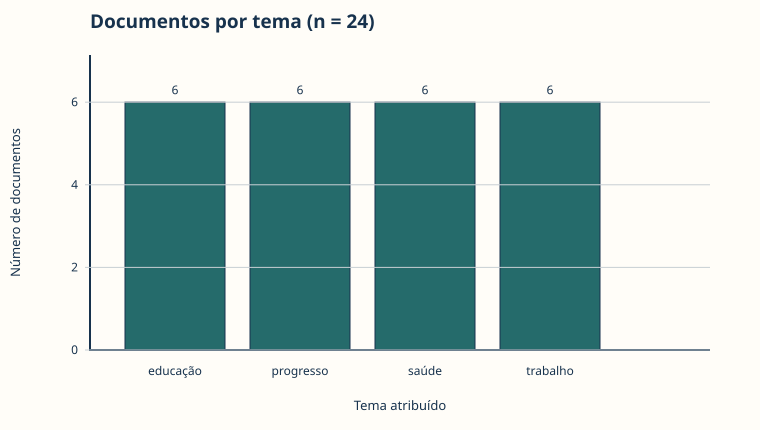

,documentos
tema,
educação,6
progresso,6
saúde,6
trabalho,6


In [3]:
tabela_temas = dados["tema"].value_counts().sort_index().rename("documentos").to_frame()
display(barras_categorias(
    tabela_temas.index.tolist(), tabela_temas["documentos"].tolist(),
    "Documentos por tema (n = 24)", "Tema atribuído", "Número de documentos",
    "Quatro barras de mesma altura mostram seis documentos em cada tema.",
))
tabela_temas

As barras anteriores representam categorias separadas. Para uma variável
quantitativa, porém, a posição dos valores e os intervalos entre eles importam;
por isso passamos a representações da distribuição.

## Histograma e boxplot — distribuições

Se os limites dos intervalos são $b_0,b_1,\ldots,b_J$, a altura da barra $j$
é a quantidade de valores dentro daquele intervalo:

$$
h_j=\sum_{i=1}^{n}\mathbf{1}(b_{j-1}<x_i\leq b_j).
$$

Alterar os limites $b_j$ pode mudar a forma visível da distribuição, mesmo sem
alterar os documentos. O boxplot aplica a regra de 1,5 IQR: os whiskers terminam
nos valores não extremos e D023 aparece como ponto separado. A tabela informa os
intervalos e o resumo numérico equivalentes.

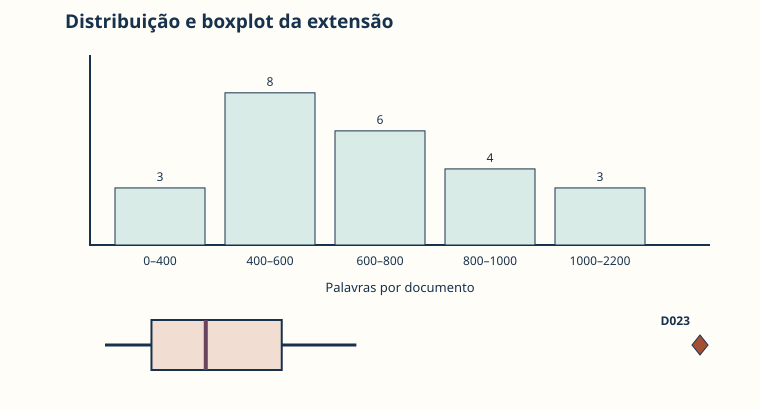

(palavras
 (0, 400]        3
 (400, 600]      8
 (600, 800]      6
 (800, 1000]     4
 (1000, 2200]    3
 Name: documentos, dtype: int64,
 count      24.000000
 mean      701.583333
 std       372.541205
 min       320.000000
 25%       459.000000
 50%       621.500000
 75%       848.750000
 max      2100.000000
 Name: palavras, dtype: float64)

In [4]:
faixas = [0, 400, 600, 800, 1000, 2200]
tabela_intervalos = dados.groupby(pd.cut(dados["palavras"], faixas), observed=False).size().rename("documentos")
display(histograma_boxplot(
    dados["palavras"].tolist(), faixas, dados["id_documento"].tolist()
))
tabela_intervalos, dados["palavras"].describe()

Histograma e boxplot descrevem uma variável quantitativa por vez. Quando a
pergunta envolve como duas quantidades variam conjuntamente, cada documento deve
ser localizado por um par de coordenadas.

## Dispersão — relação entre quantitativas

Cada ponto representa um documento. Forma e cor distinguem os gêneros, enquanto
a tabela mantém os pares e IDs disponíveis. D023 deve ser inspecionado; o padrão
visual entre páginas e palavras não demonstra causalidade.

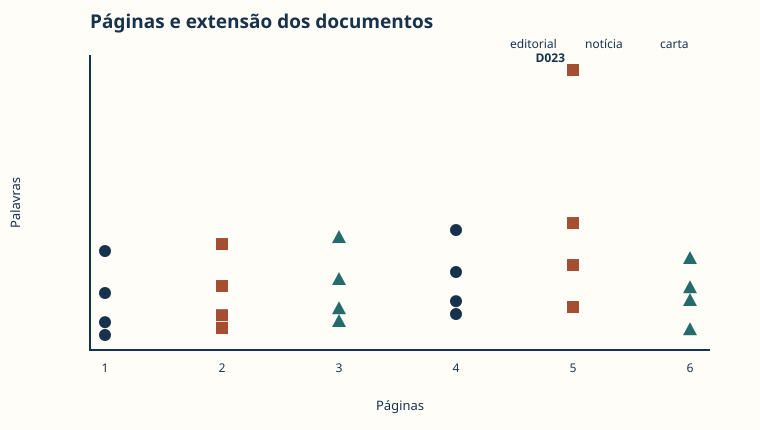

,id_documento,genero,paginas,palavras
0,D001,editorial,1,320
1,D002,notícia,2,367
2,D003,carta,3,414
3,D004,editorial,4,461
4,D005,notícia,5,508
5,D006,carta,6,555
6,D007,editorial,1,602
7,D008,notícia,2,649
8,D009,carta,3,696
9,D010,editorial,4,743


In [5]:
display(dispersao(
    dados["paginas"].tolist(), dados["palavras"].tolist(),
    dados["genero"].tolist(), dados["id_documento"].tolist(),
    "Páginas e extensão dos documentos", "Páginas", "Palavras",
))
dados[["id_documento", "genero", "paginas", "palavras"]]

O gráfico de dispersão não exige uma ordem substantiva entre os casos. Quando
uma das variáveis é o tempo, a sequência cronológica acrescenta informação, mas
também pode sugerir uma continuidade que o corpus não sustenta.

## Série temporal

Se $n_t$ documentos pertencem ao ano $t$, a média anual representada pela
linha é:

$$
\bar{x}_t=\frac{1}{n_t}\sum_{i:\,\mathrm{ano}_i=t}x_i.
$$

A fórmula torna visível o denominador anual. Mostraremos os documentos individuais
junto da média, pois cada ano contém apenas dois casos. D023 eleva a média de 1900;
a linha reflete a composição do corpus e não demonstra mudança histórica contínua.

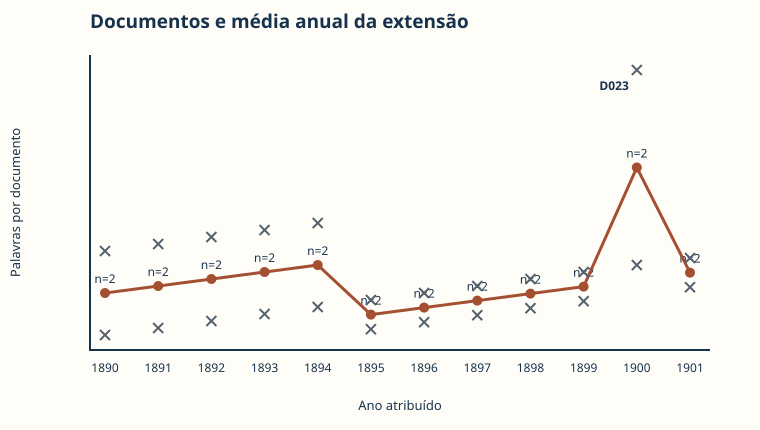

,n,media
ano,,
1890,2,602.0
1891,2,649.0
1892,2,696.0
1893,2,743.0
1894,2,790.0
1895,2,457.0
1896,2,504.0
1897,2,551.0
1898,2,598.0


In [6]:
resumo_anual = dados.groupby("ano")["palavras"].agg(n="size", media="mean")
display(serie_temporal(
    dados["ano"].tolist(), dados["palavras"].tolist(), dados["id_documento"].tolist(),
    resumo_anual["media"].to_dict(), resumo_anual["n"].to_dict(),
))
resumo_anual

Até aqui visualizamos metadados e medidas documentais. O mesmo princípio —
escolher uma forma coerente e manter uma tabela equivalente — vale para os
resultados textuais produzidos no Notebook 02.

## Frequências textuais

Barras preservam valores melhor que nuvem de palavras. A tabela informa as
frequências e o denominador deve ser lido junto das regras de tokenização e da
lista de stopwords.

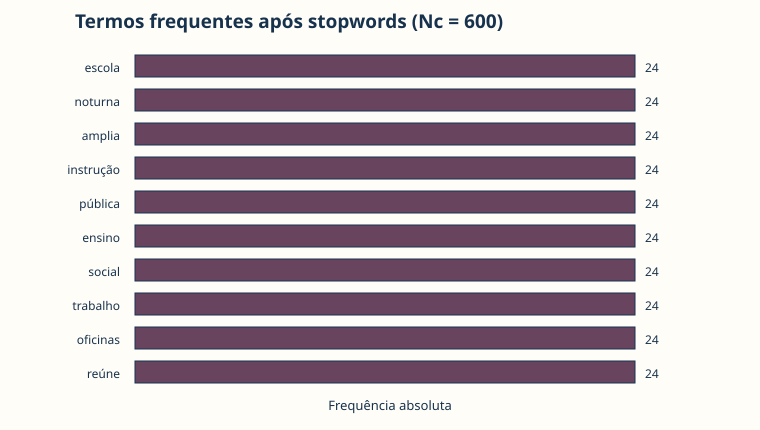

,termo,frequencia
0,escola,24
1,noturna,24
2,amplia,24
3,instrução,24
4,pública,24
5,ensino,24
6,social,24
7,trabalho,24
8,oficinas,24
9,reúne,24


In [7]:
tokens = re.findall(r"[a-záàâãéêíóôõúç]+", " ".join(dados["texto"]).lower())
stopwords = {"a", "o", "e", "de", "do", "da", "como", "em", "nas", "um", "uma", "também"}
tokens_conteudo = [token for token in tokens if token not in stopwords]
top = Counter(tokens_conteudo).most_common(10)
tabela_termos = pd.DataFrame(top, columns=["termo", "frequencia"])
ordenada = tabela_termos.sort_values("frequencia")
display(barras_horizontais(
    ordenada["termo"].tolist(), ordenada["frequencia"].tolist(),
    f"Termos frequentes após stopwords (Nc = {len(tokens_conteudo)})",
    "Dez barras horizontais ordenadas mostram frequências absolutas dos tokens de conteúdo.",
))
tabela_termos

## Aplicação ao projeto Goodreads

As células seguintes repetem as operações do notebook com a base derivada da
Unidade 3. A especificação principal de gênero da autoria é **E2** (rótulo
original, excluindo os 1.274 livros com rótulo duvidoso). E1 (rótulo original)
e E3 (duvidosos reclassificados como feminino) aparecem como sensibilidade.
Cada tabela informa a especificação e o denominador.

In [8]:
# Localiza a pasta do projeto Goodreads (localmente ou no Colab, se a pasta for enviada para /content)
import sys
from pathlib import Path

CANDIDATOS = [Path("../projeto_goodreads"), Path("projeto_goodreads"), Path("/content/projeto_goodreads")]
PROJETO = next((c.resolve() for c in CANDIDATOS if (c / "preparar_base.py").exists()), None)
if PROJETO is None:
    raise FileNotFoundError(
        "Pasta projeto_goodreads não encontrada. Coloque-a ao lado das pastas unidade_0X "
        "ou, no Colab, envie-a para /content."
    )
if str(PROJETO) not in sys.path:
    sys.path.insert(0, str(PROJETO))
print("Projeto localizado:", (PROJETO / "preparar_base.py").exists())
from preparar_base import carregar_base_analitica
import numpy as np
import pandas as pd
from IPython.display import display

base = carregar_base_analitica()
ESPEC = {"E1 original": "genero_E1_original",
         "E2 sem duvidosos (principal)": "genero_E2_sem_duvidosos",
         "E3 reclassificada": "genero_E3_reclassificado"}
GRUPO = "genero_E2_sem_duvidosos"   # especificação principal
e2 = base[base[GRUPO].notna()].copy()
print("Livros na base:", len(base), "| livros na especificação principal (E2):", len(e2))

from graficos_projeto import CORES, estilo, salvar
import matplotlib.pyplot as plt
estilo()

Projeto localizado: True
Livros na base: 10454 | livros na especificação principal (E2): 9180


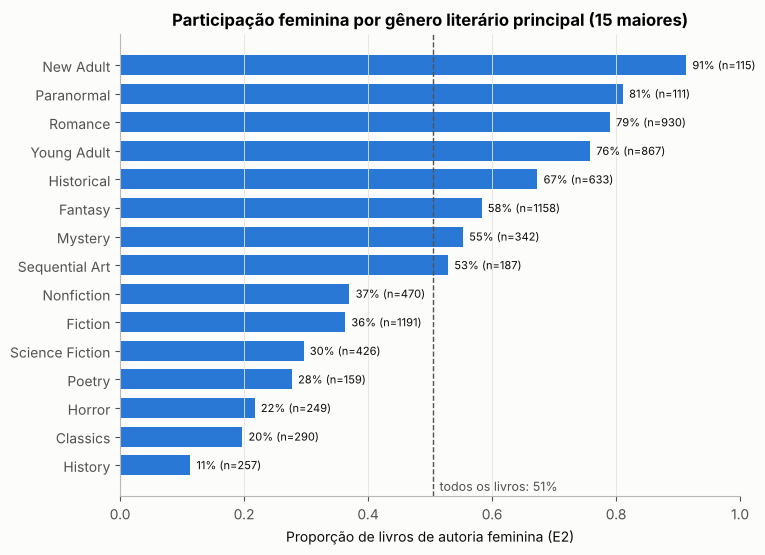

,livros,autoria_feminina,proporcao_feminina
genero_1,,,
History,257,29,0.113
Classics,290,57,0.197
Horror,249,54,0.217
Poetry,159,44,0.277
Science Fiction,426,126,0.296
Fiction,1191,432,0.363
Nonfiction,470,174,0.370
Sequential Art,187,99,0.529
Mystery,342,189,0.553


In [9]:
# Figura 1: participação de livros de autoria feminina por gênero literário (E2)
principais = e2["genero_1"].value_counts().head(15).index
tabela_fig1 = (e2[e2["genero_1"].isin(principais)]
               .groupby("genero_1")[GRUPO]
               .agg(livros="size", autoria_feminina=lambda s: s.eq("feminino").sum()))
tabela_fig1["proporcao_feminina"] = (tabela_fig1["autoria_feminina"] / tabela_fig1["livros"]).round(3)
tabela_fig1 = tabela_fig1.sort_values("proporcao_feminina")
proporcao_geral = e2[GRUPO].eq("feminino").mean()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(tabela_fig1.index, tabela_fig1["proporcao_feminina"], color=CORES["feminino"], height=0.7)
ax.axvline(proporcao_geral, color="#52514e", linewidth=1, linestyle="--")
ax.text(proporcao_geral + 0.01, -0.9, f"todos os livros: {proporcao_geral:.0%}", color="#52514e", fontsize=9)
for y, (valor, n) in enumerate(zip(tabela_fig1["proporcao_feminina"], tabela_fig1["livros"])):
    ax.text(valor + 0.01, y, f"{valor:.0%} (n={n})", va="center", fontsize=8, color="#0b0b0b")
ax.set_xlim(0, 1)
ax.set_xlabel("Proporção de livros de autoria feminina (E2)")
ax.set_title("Participação feminina por gênero literário principal (15 maiores)")
ax.grid(axis="y", visible=False)
salvar(fig, "fig1_participacao_feminina_por_genero.png")
plt.show()
tabela_fig1

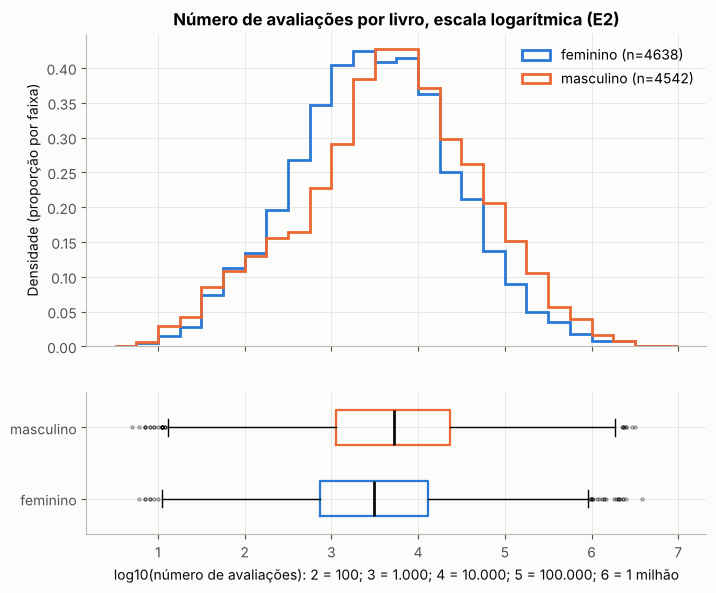

,count,mean,std,min,10%,25%,50%,75%,90%,max
genero_E2_sem_duvidosos,,,,,,,,,,
feminino,4638.0,29506.0,140789.0,6.0,202.0,747.0,3129.0,13003.0,48266.0,3819418.0
masculino,4542.0,46387.0,170612.0,5.0,172.0,1134.0,5218.0,23220.0,92646.0,3203463.0


In [10]:
# Figura 2: distribuição do número de avaliações (escala log10) por grupo (E2)
faixas = np.arange(0.5, 7.01, 0.25)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6.5), height_ratios=[2.2, 1], sharex=True)
for grupo in ["feminino", "masculino"]:
    valores = e2.loc[e2[GRUPO].eq(grupo), "log10_avaliacoes"]
    ax1.hist(valores, bins=faixas, histtype="step", linewidth=2, color=CORES[grupo],
             label=f"{grupo} (n={len(valores)})", density=True)
ax1.set_ylabel("Densidade (proporção por faixa)")
ax1.set_title("Número de avaliações por livro, escala logarítmica (E2)")
ax1.legend()
caixas = [e2.loc[e2[GRUPO].eq(g), "log10_avaliacoes"] for g in ["feminino", "masculino"]]
bp = ax2.boxplot(caixas, orientation="horizontal", tick_labels=["feminino", "masculino"], widths=0.5,
                 flierprops={"markersize": 2, "alpha": 0.4})
for caixa, grupo in zip(bp["boxes"], ["feminino", "masculino"]):
    caixa.set_color(CORES[grupo]); caixa.set_linewidth(1.6)
for mediana in bp["medians"]:
    mediana.set_color("#0b0b0b"); mediana.set_linewidth(2)
ax2.set_xlabel("log10(número de avaliações): 2 = 100; 3 = 1.000; 4 = 10.000; 5 = 100.000; 6 = 1 milhão")
salvar(fig, "fig2_distribuicao_avaliacoes_log.png")
plt.show()

tabela_fig2 = e2.groupby(GRUPO)["n_avaliacoes"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(0)
tabela_fig2

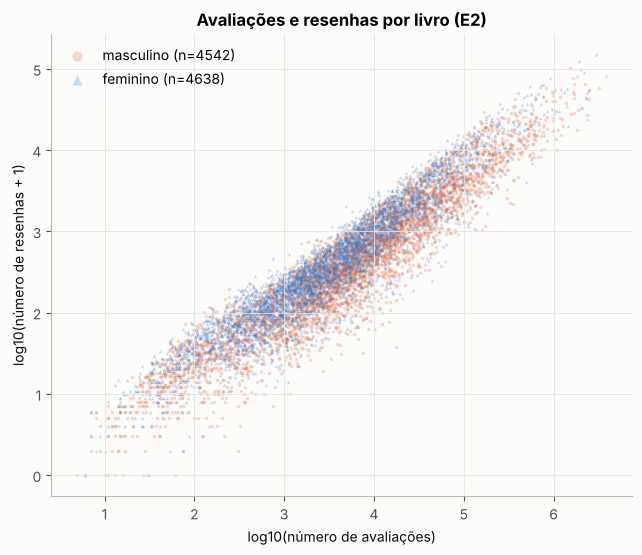

Correlação de Spearman entre avaliações e resenhas, por grupo (apenas descritiva):


genero_E2_sem_duvidosos
feminino     0.940
masculino    0.938
Name: n_avaliacoes, dtype: float64

size             median          
genero_E2_sem_duvidosos feminino masculino feminino masculino
faixa_avaliacoes                                             
até 1 mil                   1368      1082    0.213     0.179
1 mil a 10 mil              1913      1739    0.110     0.079
10 mil a 100 mil            1116      1292    0.081     0.056
acima de 100 mil             241       429    0.053     0.036

In [11]:
# Figura 3: avaliações × resenhas (log-log), cada ponto é um livro (E2)
fig, ax = plt.subplots(figsize=(7.5, 6))
for grupo, marcador in [("masculino", "o"), ("feminino", "^")]:
    dados = e2[e2[GRUPO].eq(grupo)]
    ax.scatter(dados["log10_avaliacoes"], dados["log10_resenhas_mais_1"], s=6, alpha=0.25,
               color=CORES[grupo], marker=marcador, label=f"{grupo} (n={len(dados)})", linewidths=0)
ax.set_xlabel("log10(número de avaliações)")
ax.set_ylabel("log10(número de resenhas + 1)")
ax.set_title("Avaliações e resenhas por livro (E2)")
ax.legend(markerscale=3)
salvar(fig, "fig3_avaliacoes_resenhas.png")
plt.show()

print("Correlação de Spearman entre avaliações e resenhas, por grupo (apenas descritiva):")
display(e2.groupby(GRUPO)[["n_avaliacoes", "n_resenhas"]].corr(method="spearman").xs("n_resenhas", level=1)["n_avaliacoes"].round(3))
tabela_fig3 = e2.assign(faixa_avaliacoes=pd.cut(e2["n_avaliacoes"], [0, 1_000, 10_000, 100_000, 10_000_000],
                                                labels=["até 1 mil", "1 mil a 10 mil", "10 mil a 100 mil", "acima de 100 mil"]))
tabela_fig3 = tabela_fig3.groupby(["faixa_avaliacoes", GRUPO], observed=True)["taxa_resenhas"].agg(["size", "median"]).round(3).unstack()
tabela_fig3

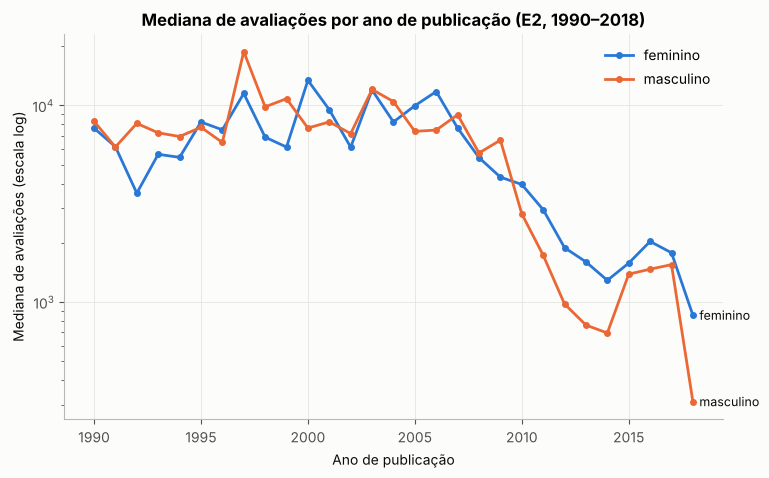

n            mediana          
genero_E2_sem_duvidosos feminino masculino feminino masculino
ano_publicacao                                               
1990                          18        41   7664.0    8301.0
1991                          18        31   6163.5    6145.0
1992                          29        47   3578.0    8103.0
1993                          24        46   5641.5    7255.5
1994                          22        39   5443.0    6948.0
1995                          30        52   8232.5    7744.5
1996                          33        46   7516.0    6481.0
1997                          35        53  11507.0   18790.0
1998                          37        56   6895.0    9837.5
1999                          38        47   6139.5   10825.0
2000                          41        71  13423.0    7672.0
2001                          55        67   9512.0    8248.0
2002                          47        79   6129.0    7190.0
2003                          59        93  11981.0   12057.0
2004                          57       113   8241.0   10461.0
2005                          77        86   9968.0    7382.5
2006                          86       111  11768.5    7493.0
2007                          89       122   7674.0    8966.0
2008                         136       151   5423.5    5727.0
2009                         180       122   4316.0    6660.0
2010                         238       150   3962.0    2808.0
2011                         347       206   2948.0    1729.0
2012                         514       267   1888.0     976.0
2013                         662       292   1599.0     762.5
2014                         471       231   1288.0     695.0
2015                         315       142   1576.0    1385.0
2016                         204       118   2032.0    1468.0
2017                         119        75   1779.0    1548.0
2018                         163        31    856.0     311.0

In [12]:
# Figura 4: mediana de avaliações por ano de publicação, 1990–2018 (E2)
recorte = e2[e2["ano_publicacao"].between(1990, 2018)]
tabela_fig4 = recorte.groupby(["ano_publicacao", GRUPO])["n_avaliacoes"].agg(n="size", mediana="median").unstack()
fig, ax = plt.subplots(figsize=(8.5, 5))
for grupo in ["feminino", "masculino"]:
    serie = tabela_fig4[("mediana", grupo)]
    ax.plot(serie.index, serie.values, color=CORES[grupo], linewidth=2, marker="o", markersize=4, label=grupo)
    ax.text(serie.index[-1] + 0.3, serie.values[-1], grupo, color="#0b0b0b", fontsize=9, va="center")
ax.set_yscale("log")
ax.set_xlabel("Ano de publicação")
ax.set_ylabel("Mediana de avaliações (escala log)")
ax.set_title("Mediana de avaliações por ano de publicação (E2, 1990–2018)")
ax.legend(loc="upper right")
salvar(fig, "fig4_mediana_por_ano.png")
plt.show()
tabela_fig4

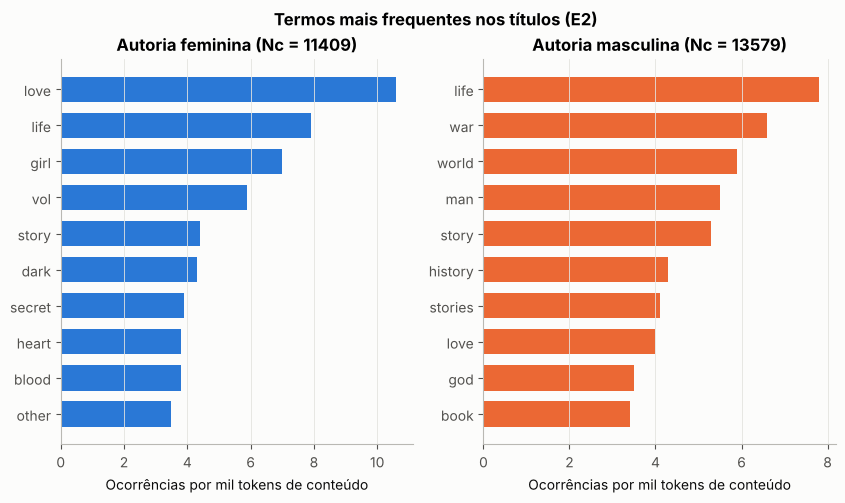

,grupo,termo,frequencia,por_mil_tokens
0,feminino,love,121,10.6
1,feminino,life,90,7.9
2,feminino,girl,80,7.0
3,feminino,vol,67,5.9
4,feminino,story,50,4.4
5,feminino,dark,49,4.3
6,feminino,secret,45,3.9
7,feminino,blood,43,3.8
8,feminino,heart,43,3.8
9,feminino,other,40,3.5


In [13]:
# Figura 5: termos de conteúdo mais frequentes nos títulos, por grupo (E2)
import re
from collections import Counter
STOPWORDS_EN = {"the", "a", "an", "of", "and", "in", "to", "for", "on", "at", "with", "from",
                "by", "my", "your", "is", "or", "her", "his", "our", "their", "its", "be",
                "as", "into", "about", "this", "that", "what", "how", "who", "when", "you",
                "me", "i", "it", "not", "no", "all", "one", "s", "de", "la", "el", "le"}
tokens = e2["titulo"].map(lambda t: [w for w in re.findall(r"[^\W\d_]+", str(t).casefold()) if w not in STOPWORDS_EN])
fig, eixos = plt.subplots(1, 2, figsize=(10, 5), sharex=False)
tabelas_fig5 = {}
for ax, grupo in zip(eixos, ["feminino", "masculino"]):
    lista = [w for ts in tokens[e2[GRUPO].eq(grupo)] for w in ts]
    top = pd.DataFrame(Counter(lista).most_common(10), columns=["termo", "frequencia"])
    top["por_mil_tokens"] = (top["frequencia"] / len(lista) * 1000).round(1)
    tabelas_fig5[grupo] = top
    ordenada = top.sort_values("por_mil_tokens")
    ax.barh(ordenada["termo"], ordenada["por_mil_tokens"], color=CORES[grupo], height=0.7)
    ax.set_title(f"Autoria {grupo.replace('ino', 'ina')} (Nc = {len(lista)})")
    ax.set_xlabel("Ocorrências por mil tokens de conteúdo")
    ax.grid(axis="y", visible=False)
fig.suptitle("Termos mais frequentes nos títulos (E2)", fontweight="bold")
salvar(fig, "fig5_termos_titulos.png")
plt.show()
pd.concat(tabelas_fig5, names=["grupo"]).reset_index(level=0)

As cinco famílias mostraram que um gráfico não é uma etapa automática após o
cálculo: sua forma depende da pergunta, da variável e do limite que precisa
permanecer visível. A atividade transforma essas escolhas em um pequeno conjunto
de argumentos gráficos para a oficina.

## U04-A04 — Atividade — visualização exploratória

Produza barras, histograma/boxplot, dispersão ou tempo e frequência textual. Para
cada figura, entregue tabela, descrição alternativa, escala, padrão, caso, limite
e hipótese. Explique também por que o gráfico escolhido responde à pergunta.

**Minha análise** (figuras e tabelas nas células anteriores; arquivos PNG em
`projeto_goodreads/figuras/`; especificação E2, n = 9.180):

**Figura 1. Barras: participação feminina por gênero literário.**
*Pergunta:* como a autoria feminina se distribui entre os gêneros literários?
*Por que barras:* comparar uma proporção entre categorias nominais; barras
horizontais acomodam nomes longos e permitem ordenar. *Escala:* proporção de 0
a 1, com o número de livros de cada barra. *Descrição alternativa:* quinze
barras horizontais ordenadas, de History (11%, n = 257) a New Adult (91%,
n = 115); linha tracejada em 51% marca a proporção geral. *Padrão:* forte
segregação: gêneros de prestígio acadêmico ou associados a temas masculinos
têm poucas autoras; romance e jovem adulto, muitas. *Caso:* Fantasy está perto
do equilíbrio (58%). *Limite:* descreve a composição do recorte, não a
produção editorial. *Hipótese:* comparações agregadas entre grupos misturam
diferenças entre gêneros literários.

**Figura 2. Histograma e boxplot: distribuição do número de avaliações.**
*Pergunta:* como o alcance se distribui em cada grupo? *Por que:* variável
quantitativa muito assimétrica; o histograma mostra a forma, o boxplot mostra
quartis e casos sinalizados. *Escala:* log10 do número de avaliações (3 = mil;
5 = cem mil). *Descrição alternativa:* duas curvas em degrau parecidas, com pico
entre mil e dez mil avaliações; a curva de autoria masculina está levemente
deslocada para a direita; nos boxplots, a caixa masculina começa e termina à
direita da feminina. *Tabela:* percentis 10, 25, 50, 75 e 90 (por exemplo,
percentil 90 de 48.266 para autoras e 92.646 para autores). *Padrão:* as
distribuições se sobrepõem muito; a diferença está mais no centro e na cauda
superior. *Caso:* no percentil 10, autoras têm valor maior (202 contra 172).
*Limite:* a escala log comprime diferenças grandes. *Hipótese:* a diferença
cresce entre os livros mais avaliados.

**Figura 3. Dispersão: avaliações e resenhas.**
*Pergunta:* livros com mais avaliações têm proporcionalmente mais resenhas, e
isso difere entre grupos? *Por que dispersão:* duas quantitativas no mesmo
livro. *Escala:* log-log. *Descrição alternativa:* nuvem densa e alongada em
diagonal; triângulos azuis (autoras) ficam ligeiramente acima dos círculos
laranja (autores) para o mesmo número de avaliações. *Tabela:* mediana da taxa
de resenhas por faixa de avaliações: em todas as faixas a taxa é maior para
autoras (por exemplo, 0,110 contra 0,079 entre mil e dez mil avaliações).
Correlação de Spearman de 0,94 nos dois grupos, apenas descritiva. *Padrão:* a
taxa cai à medida que o livro fica mais avaliado. *Caso:* *The Fault in Our
Stars* (John Green) tem o maior número de resenhas do recorte (147.696).
*Limite:* não mostra causalidade nem o teor das resenhas. *Hipótese:* livros de
autoras mobilizam mais escrita por leitor, em todas as faixas de alcance.

**Figura 4. Série temporal: mediana de avaliações por ano (1990–2018).**
*Pergunta:* a diferença entre grupos é estável no tempo? *Por que linha:* o ano
é ordenado. *Escala:* mediana em escala log; a tabela mostra n por ano.
*Descrição alternativa:* duas linhas que se cruzam várias vezes até 2009 e, a
partir de 2010, a linha azul (autoras) fica sempre acima da laranja (autores).
*Padrão:* para livros publicados entre 2010 e 2018, a mediana de livros de
autoras é maior em todos os anos (por exemplo, 1.599 contra 763 em 2013). *Caso
inesperado:* isso contraria o resultado agregado. *Limite:* poucos livros em
alguns anos (31 de autores em 2018); medianas anuais oscilam. *Hipótese:* a
diferença agregada resulta em boa parte da composição temporal: livros de
autores são mais antigos e acumularam avaliações por mais tempo, e livros
recentes de autoras são muito numerosos.

**Figura 5. Barras de frequência textual nos títulos.**
*Pergunta:* que palavras dominam os títulos de cada grupo? *Por que barras:*
preservam valores melhor que nuvem de palavras. *Escala:* ocorrências por mil
tokens de conteúdo, com Nc de cada grupo no título do painel. *Descrição
alternativa:* dois painéis; à esquerda (autoras) *love* lidera com 10,6 por
mil; à direita (autores) *life* lidera com 7,8, seguida de *war*. *Limite:*
títulos não são o texto dos livros. *Hipótese:* convenções de título acompanham
gêneros literários.

**Quatro figuras selecionadas para o relatório:** 1 (composição por gênero),
2 (distribuição do alcance), 3 (engajamento relativo) e 4 (tempo). A figura 5
fica como complemento, porque repete em parte a informação da figura 1.